# NFF5 PR2 — Aaron's Guided FEM Benchmarking & Validation Tutorial

**Purpose:** Run an evidence-based comparison of our existing TMS FEM results, document the source of every number, and identify what still needs verification before we describe a commercial-coil performance advantage.

**You are not being asked to run new FEM simulations.** Cortney, Rafael, and Brandon already produced the data used here. Your role is to *trace it, check it, interpret it, and explain it accurately* for PR2.

**What you will produce:** a mesh inventory with file hashes, ROI metrics, a descriptive plot, a team comparability audit, a cross-check of the saved ROI values, Brandon's optimization provenance review, and a short scientific decision memo. These files are saved in `aaron_pr2_outputs` beside this notebook.

**How to work:** Read the explanation immediately above each code cell, run that cell with **Shift+Enter**, and compare the result with the checkpoint described in the text. Do not jump ahead if a required file is missing. A `REVIEW` or `PROVISIONAL` flag is a legitimate scientific outcome—not a reason to edit the result until it says PASS.

**Important:** A readable file, a reproducible number, and a physically fair comparison are three different levels of evidence. This notebook deliberately distinguishes them.

## Cell 1 — Connect your computer to the existing project data

**What you are doing:** telling Python where the files already live. Think of this as making a map of the project, *not* copying files into a new folder. The paths below are Victor's **known working examples**, so they may not work unchanged on your computer.

**Before you run this cell:**

1. Open this `.ipynb` file in Jupyter using a Python environment with **SimNIBS**, `numpy`, `pandas`, and `matplotlib` available.
2. In the code below, change **`PROJECT`** to the location of your shared `reference Notebooks` folder. If you have the same Google Drive mapping and folder layout, Victor's example can remain unchanged.
3. Change **`ERNIE_DIR`** to the actual `m2m_ernie` folder in *your* SimNIBS installation. The `C:\Users\prncf\...` path is Victor's machine, not a universal location.
4. Change **`MAGSTIM_MSH`** to the actual Magstim-named baseline `.msh` file on your computer. The example uses Victor's separate `G:\My Drive\ASU\capstone\...` tutorial directory.
5. If your teammates' folders are arranged differently, edit **`CORTNEY_DIR`**, **`CORTNEY_JSON`**, **`RAFI_DIR`**, **`RAFI_VECTOR_DIR`**, **`BRANDON_CSV`**, and **`BRANDON_PROVENANCE`** individually. Do **not** rename, move, or rerun their existing simulation files just to match this tutorial.
6. Leave **`ROOT`**, **`INPUT`**, **`OUTPUT`**, and **`TEAM_CSV`** alone: these are local output locations, and the notebook generates the handoff CSV automatically from real saved meshes.

**Checkpoint:** the output should say `SETUP PATH CHECK PASSED`, list the Magstim mesh and Ernie subject as present, and ideally discover **four** NFF5 meshes: Cortney C01 plus Rafael P1, P2, P3. If you see `PENDING`, fix the relevant path in this cell; don't fabricate replacement inputs.

**Scientific caution:** The fields named `REFERENCE_...` are intentionally blank until the commercial reference's coil source, excitation, placement, orientation, and scalp offset can be documented. Do not fill them with guesses just to unlock a comparison.

## Why we're measuring an electric field (brief physics context)

A changing coil current creates a time-varying magnetic field, which induces an electric field in tissue. In the quasistatic model used for TMS, we can write

$$\mathbf E=-\frac{\partial\mathbf A}{\partial t}-\nabla\phi,\qquad \mathbf J=\boldsymbol\sigma\mathbf E.$$

Here $\mathbf A$ is magnetic vector potential, $\phi$ is electric scalar potential, and $\boldsymbol\sigma$ represents tissue conductivity. **Your practical takeaway:** the anatomical mesh and stimulation configuration determine the electric field we extract. The value of a field is meaningful only with its source settings and units.

**Process priority:** you'll mostly be checking *what was simulated, where the result is stored, which anatomical elements were selected, and whether comparisons use matched conditions*.

In [2]:
from pathlib import Path
import sys, json, csv, re, hashlib, datetime, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# AARON: These are Victor's working example paths. Change PROJECT, ERNIE_DIR,
# MAGSTIM_MSH and any team-data paths that differ on YOUR computer.
# Keep the output directories as written; do not move or recreate FEM data.
PROJECT = Path(r'C:\Users\aaron\Desktop\EEE488\PR2\Reference Notebooks')
ROOT = Path.cwd()  # output stays beside whichever notebook is running
INPUT = ROOT / 'inputs'; MESH_DIR = INPUT / 'meshes'; OUTPUT = ROOT / 'aaron_pr2_outputs'
for directory in (INPUT, MESH_DIR, OUTPUT): directory.mkdir(parents=True, exist_ok=True)
ERNIE_DIR = Path(r'C:\Users\aaron\simnibs4_examples\m2m_ernie')
MAGSTIM_MSH = Path(r'C:\Users\aaron\NFF5_PR2_Magstim_DLPFC\Magstim_Fig8_DLPFC_20261027_201339_544149\ernie_TMS_1-0001_Magstim_70mm_Fig8_scalar.msh'
)
CORTNEY_DIR = PROJECT / 'Cortney' / 'data' / 'NFF5_CORT_C01_output'
CORTNEY_JSON = CORTNEY_DIR / 'run_manifest.json'
RAFI_DIR = PROJECT / 'rafi' / 'data' / 'three_positions'
RAFI_VECTOR_DIR = PROJECT / 'rafi' / 'data' / 'three_positions_vectors'
BRANDON_CSV = PROJECT / 'brandon' / 'data' / 'fem_optimization' / 'PR2_3Coil_Opti_v01.csv'
BRANDON_PROVENANCE = PROJECT / 'brandon' / 'data' / 'fem_optimization' / 'PR2_3Coil_Opti_v01.json'
TEAM_CSV = INPUT / 'nff5_team_roi_results.csv'  # created automatically from saved FEM meshes
CUSTOM_DIDT_A_PER_S = 1.5e8  # documented custom-coil setting; verify each source before controlled comparison

def find_one_mesh(folder, label):
    folder = Path(folder)
    matches = sorted(folder.rglob('*.msh')) if folder.is_dir() else []
    matches = [p for p in matches if p.name.endswith('_scalar.msh')] or matches
    if len(matches) > 1:
        raise RuntimeError(f'Ambiguous {label} meshes: ' + ', '.join(map(str,matches)))
    return matches[0] if matches else None

CASE_MESHES = {'Cortney_C01':find_one_mesh(CORTNEY_DIR,'Cortney')}
for pos in ('P1','P2','P3'):
    # Prefer scalar results; vector directory is a fallback, never double-count a position.
    CASE_MESHES['Rafael_'+pos] = (find_one_mesh(RAFI_DIR/pos,'Rafael '+pos)
                                    or find_one_mesh(RAFI_VECTOR_DIR/pos,'Rafael vector '+pos))
NFF5_MSH_FILES = [p for p in CASE_MESHES.values() if p is not None]
CORTNEY_MSH = CASE_MESHES['Cortney_C01']
print('=== ALL EXTERNAL DEPENDENCIES ===')
for label,path in [('Ernie subject',ERNIE_DIR),('Magstim baseline',MAGSTIM_MSH),
                   ('Cortney results JSON',CORTNEY_JSON),('Cortney FEM directory',CORTNEY_DIR),
                   ('Rafael scalar directory',RAFI_DIR),('Rafael vector directory',RAFI_VECTOR_DIR),
                   ('Brandon comparison CSV',BRANDON_CSV),('Brandon provenance JSON',BRANDON_PROVENANCE)]:
    print(f'{label:26} {"FOUND" if path.exists() else "PENDING"}: {path}')
for label,path in CASE_MESHES.items():
    print(f'{label:26} {path if path else "PENDING (no mesh discovered)"}')
MNI_CENTER = np.array([-38., 44., 26.]); ROI_RADIUS_MM = 10.0; GM_TAG = 2
# Record measured/documented settings, never infer from mesh filenames:
REFERENCE_COIL_FILE = 'Magstim_70mm_Fig8.ccd'
REFERENCE_COIL_SOURCE = 'SimNIBS 4.6 bundled coil model'
REFERENCE_PLACEMENT = 'Left DLPFC, MNI (-38, 44, 26)'
REFERENCE_ORIENTATION = 'Posterior reference, Y offset (0, -20, 0) mm'
REFERENCE_DIDT_A_PER_S = 1.5e8
REFERENCE_SCALP_OFFSET_MM = 4.0
HEAD_MODEL_ID = 'ernie'
try: SIMNIBS_VERSION = importlib.metadata.version('simnibs')
except importlib.metadata.PackageNotFoundError: SIMNIBS_VERSION = 'not detected'
print('SimNIBS:',SIMNIBS_VERSION,'| Python:',sys.version.split()[0]); print('NFF5 meshes:',len(NFF5_MSH_FILES))
print('Reference present:',MAGSTIM_MSH.is_file(),'| Subject present:',ERNIE_DIR.exists())
print('Python executable:',sys.executable)
print('Working directory:',ROOT.resolve())
print('Subject directory:',ERNIE_DIR,'| exists:',ERNIE_DIR.is_dir())
print('Reference mesh:',MAGSTIM_MSH,'| exists:',MAGSTIM_MSH.is_file())
print('Team CSV:',TEAM_CSV,'| exists:',TEAM_CSV.is_file())
print('Detected NFF5 files:',*[str(p) for p in NFF5_MSH_FILES],sep='\n  ')
if not ERNIE_DIR.is_dir() or not MAGSTIM_MSH.is_file():
    print('SETUP INCOMPLETE: correct the missing required paths before running later cells.')
else:
    print('SETUP PATH CHECK PASSED: proceed to provenance and data-content validation.')


print("Magstim:", "FOUND" if MAGSTIM_MSH.is_file() else "MISSING")
print("Cortney:", "FOUND" if (CORTNEY_DIR / "ernie_TMS_1-0001_NFF5_CORT_C01_scalar.msh").is_file() else "MISSING")  


=== ALL EXTERNAL DEPENDENCIES ===
Ernie subject              FOUND: C:\Users\aaron\simnibs4_examples\m2m_ernie
Magstim baseline           FOUND: C:\Users\aaron\NFF5_PR2_Magstim_DLPFC\Magstim_Fig8_DLPFC_20261027_201339_544149\ernie_TMS_1-0001_Magstim_70mm_Fig8_scalar.msh
Cortney results JSON       FOUND: C:\Users\aaron\Desktop\EEE488\PR2\Reference Notebooks\Cortney\data\NFF5_CORT_C01_output\run_manifest.json
Cortney FEM directory      FOUND: C:\Users\aaron\Desktop\EEE488\PR2\Reference Notebooks\Cortney\data\NFF5_CORT_C01_output
Rafael scalar directory    FOUND: C:\Users\aaron\Desktop\EEE488\PR2\Reference Notebooks\rafi\data\three_positions
Rafael vector directory    FOUND: C:\Users\aaron\Desktop\EEE488\PR2\Reference Notebooks\rafi\data\three_positions_vectors
Brandon comparison CSV     FOUND: C:\Users\aaron\Desktop\EEE488\PR2\Reference Notebooks\brandon\data\fem_optimization\PR2_3Coil_Opti_v01.csv
Brandon provenance JSON    FOUND: C:\Users\aaron\Desktop\EEE488\PR2\Reference Notebooks\br

## Cell 2 — Fingerprint the saved FEM files

**Goal:** create a provenance inventory. A SHA-256 hash is like a digital fingerprint: if the file bytes change, its hash changes with overwhelming probability. This helps us show exactly which mesh version was analyzed.

**Do:** run the next cell; it reads each existing mesh and saves a table. **Expect:** one baseline plus up to four team meshes, with sizes and hashes. **Don't conclude:** matching hashes or successful file reads prove the coil geometry or stimulation parameters are correct—they don't.

In [3]:
def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(1024*1024), b''): h.update(block)
    return h.hexdigest()

all_meshes = ([MAGSTIM_MSH] if MAGSTIM_MSH.is_file() else []) + NFF5_MSH_FILES
manifest = pd.DataFrame([{'filename':p.name,'bytes':p.stat().st_size,'sha256':sha256_file(p)} for p in all_meshes],
                        columns=['filename','bytes','sha256'])
manifest.to_csv(OUTPUT/'input_manifest.csv',index=False)
provenance = {'created_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
              'simnibs_version':SIMNIBS_VERSION,'head_model':HEAD_MODEL_ID,
              'subject_dir':str(ERNIE_DIR),'mni_center_mm':MNI_CENTER.tolist(),
              'radius_mm':ROI_RADIUS_MM,'gm_tag':GM_TAG,
              'reference_mesh':str(MAGSTIM_MSH) if MAGSTIM_MSH.exists() else None,
              'reference_coil_file':REFERENCE_COIL_FILE,'reference_coil_source':REFERENCE_COIL_SOURCE,
              'reference_placement':REFERENCE_PLACEMENT,'reference_orientation':REFERENCE_ORIENTATION,
              'reference_didt_A_per_s':REFERENCE_DIDT_A_PER_S,
              'reference_scalp_offset_mm':REFERENCE_SCALP_OFFSET_MM}
(OUTPUT/'provenance.json').write_text(json.dumps(provenance,indent=2),encoding='utf-8')
print(manifest.to_string(index=False) if len(manifest) else 'No meshes supplied yet; manifest is empty.')

                                     filename     bytes                                                           sha256
ernie_TMS_1-0001_Magstim_70mm_Fig8_scalar.msh 397097513 e3e644efa6f0c2c7ac8fe45e5a1c08ce1c513b531cec1d5aa8111cee626392d2
    ernie_TMS_1-0001_NFF5_CORT_C01_scalar.msh 240944426 596648e8f0328bc58f09f50633a3e45fb9cbc3075bb725b3925d7343a6854eb3
                    NFF5_PR2_C20_P1_E_v01.msh 397097513 93af4962ac0757ffe625c66ed17fe29ae527d895685dc9680043c59474f6ce75
                    NFF5_PR2_C20_P2_E_v01.msh 397097513 25dfa76e4b87ea1ed3f2977d5b3e0407cb5bef5f2d88c3721bcf37ca958e380b
                    NFF5_PR2_C20_P3_E_v01.msh 397097513 721f513c20f2142f46b269374f0ce58720b328545a42d0cf6fe3c9663c453cd1


## Cell 3 — Put the DLPFC target into Ernie's coordinates

**Goal:** convert our agreed standardized target, **MNI $(-38,44,26)$ mm**, to the coordinate system of the Ernie head mesh. This matters because the mesh tetrahedra are positioned in *subject space*, not in MNI space.

**Do:** run the next cell. **Expected reference result on Victor's Ernie model:** approximately $(-33.71,70.75,43.77)$ mm. A mismatch deserves investigation of the subject folder and transformation, not a manually adjusted coordinate.

We define a **10 mm radius** sphere (20 mm diameter), not a 10 mm diameter sphere. Later we include only gray-matter tetrahedra whose centroids fall inside this sphere. For PR2, explain the transformation and selection in plain language; you do not need to derive the registration algorithm.

In [4]:
subject_center = None
if ERNIE_DIR.exists():
    try:
        from simnibs.utils import transformations
        subject_center = np.asarray(transformations.mni2subject_coords(MNI_CENTER.tolist(),str(ERNIE_DIR)),dtype=float).reshape(3)
        assert np.isfinite(subject_center).all()
        print('Subject ROI center (mm):',subject_center)
    except Exception as exc: print('BLOCKED: subject transform:',type(exc).__name__,str(exc)[:250])
else: print('BLOCKED: set ERNIE_DIR to the actual subject directory.')

Subject ROI center (mm): [-33.71040726  70.74802399  43.76509094]


## Cell 4 — Extract the actual ROI metric from each saved FEM mesh

**Goal:** turn a large anatomical electric-field solution into one well-defined, reproducible measurement for each case.

**Procedure:** open each `.msh`, find its element-wise electric-field magnitude (`magnE` or `E_magn`), select **gray-matter tetrahedra** inside the transformed 10 mm ROI, and calculate a **volume-weighted mean**:

$$\overline{|\mathbf E|}_{\mathrm{GM,ROI}}=\frac{\sum_{i\in\mathrm{ROI}}V_i|\mathbf E_i|}{\sum_{i\in\mathrm{ROI}}V_i}.$$

The volume weighting prevents small tetrahedra from counting as much as large ones merely because there are more of them. The resulting unit is **V/m**. The reported gray-matter ROI volume is *not* the full geometric sphere volume, because only eligible GM tetrahedra count.

**Do:** run the cell. **Expect:** a Magstim-named baseline plus Cortney C01 and Rafael P1–P3, provided all paths are connected. The cell also builds `inputs/nff5_team_roi_results.csv` from the **actual saved meshes**; Aaron does not need to type or invent this CSV.

**Record:** the output values and number of ROI elements. **Do not claim yet:** a larger number proves the new coil is superior; excitation and geometry must first be checked.

In [5]:
def extract_roi_metric(mesh_path, center, radius_mm=10.0, gm_tag=2):
    from simnibs import mesh_io
    mesh = mesh_io.read_msh(str(mesh_path))
    fields = [f for f in mesh.elmdata if f.field_name in ('magnE','E_magn')]
    if not fields: raise ValueError('No element-wise magnE/E_magn field; review actual FEM export.')
    if len(fields)>1: raise ValueError('Ambiguous multiple magnitude fields; select verified field explicitly.')
    e = np.asarray(fields[0].value,dtype=float).reshape(-1)
    tags = np.asarray(mesh.elm.tag1).reshape(-1)
    types = np.asarray(mesh.elm.elm_type).reshape(-1)
    xyz = np.asarray(mesh.elements_baricenters().value,dtype=float)
    vol = np.asarray(mesh.elements_volumes_and_areas().value,dtype=float).reshape(-1)
    if not (len(e)==len(tags)==len(types)==len(xyz)==len(vol)):
        raise ValueError('Mesh arrays/field length mismatch')
    mask = (types==4)&(tags==gm_tag)&(np.linalg.norm(xyz-center,axis=1)<=radius_mm)
    mask &= np.isfinite(e)&np.isfinite(vol)&(vol>0)
    if not mask.any(): raise ValueError('No valid gray-matter tetrahedra within ROI')
    values=e[mask]; weights=vol[mask]
    return {'case':mesh_path.stem,'mean_E_V_per_m':float(np.average(values,weights=weights)),
            'max_E_V_per_m':float(values.max()),'n_elements':int(mask.sum()),
            'gm_volume_mm3':float(weights.sum()),'roi_center_subject_mm':np.asarray(center).tolist(),
            'mesh_path':str(mesh_path),'field_name':fields[0].field_name}

results=[]; errors=[]
if subject_center is not None:
    for path in all_meshes:
        try: results.append(extract_roi_metric(path,subject_center,ROI_RADIUS_MM,GM_TAG))
        except Exception as exc: errors.append({'file':path.name,'error':f'{type(exc).__name__}: {exc}'})
else: print('Mesh extraction withheld: subject transform not verified.')
metrics=pd.DataFrame(results); metrics.to_csv(OUTPUT/'mesh_roi_metrics.csv',index=False)
pd.DataFrame(errors,columns=['file','error']).to_csv(OUTPUT/'mesh_errors.csv',index=False)
print(metrics[['case','mean_E_V_per_m','n_elements','gm_volume_mm3']].to_string(index=False) if len(metrics) else 'No verified mesh metrics yet.')
if errors: print('Mesh issues:',errors)

# AUTOMATED HANDOFF — no manual CSV construction and no FEM solver reruns.
# Only completed, successfully extracted meshes enter the handoff.
mesh_to_case = {str(p):case for case,p in CASE_MESHES.items() if p is not None}
handoff_rows=[]
for item in results:
    p=item['mesh_path']
    if p == str(MAGSTIM_MSH):
        continue  # baseline is retained separately; it is not a candidate team case
    case=mesh_to_case.get(p)
    if case is None:
        continue
    handoff_rows.append({
        'case':case, 'mean_E_V_per_m':item['mean_E_V_per_m'],
        'head_model':HEAD_MODEL_ID, 'roi_center_mni':'(-38, 44, 26)',
        'roi_radius_mm':ROI_RADIUS_MM,
        'didt_A_per_s':CUSTOM_DIDT_A_PER_S,
        'coil_source':'NFF5_CORT_C01 custom coil (verify run configuration)',
        'notes':'Computed from saved FEM mesh; excitation and placement require source provenance verification',
        'placement':case if case.startswith('Rafael_') else '',
        'orientation':'', 'scalp_offset_mm':np.nan,
        'method':'GM tetrahedra, centroid inclusion, volume-weighted mean |E|',
        'mesh_file':p})
required_handoff=['case','mean_E_V_per_m','head_model','roi_center_mni','roi_radius_mm',
                  'didt_A_per_s','coil_source','notes','placement','orientation',
                  'scalp_offset_mm','method','mesh_file']
pd.DataFrame(handoff_rows,columns=required_handoff).to_csv(TEAM_CSV,index=False)
print(f'Automatic team handoff: {TEAM_CSV} | real mesh cases: {len(handoff_rows)}')
if not handoff_rows: print('WARNING: No custom-coil meshes available; check paths above.')


                                     case  mean_E_V_per_m  n_elements  gm_volume_mm3
ernie_TMS_1-0001_Magstim_70mm_Fig8_scalar      160.946951        4091     1983.98689
    ernie_TMS_1-0001_NFF5_CORT_C01_scalar        1.809869        4091     1983.98689
                    NFF5_PR2_C20_P1_E_v01        2.612401        4091     1983.98689
                    NFF5_PR2_C20_P2_E_v01        2.812810        4091     1983.98689
                    NFF5_PR2_C20_P3_E_v01        2.673750        4091     1983.98689
Automatic team handoff: C:\Users\aaron\Desktop\EEE488\PR2\inputs\nff5_team_roi_results.csv | real mesh cases: 4


### Optional diagnostic — inspect the distribution, not just its average

**Goal:** look for unexpectedly extreme field values or suspiciously sparse ROI sampling. The mean is useful for comparison, but it doesn't show the entire distribution. Run this cell and note whether the median, high-percentile value, and element count look reasonable. This is a numerical sanity check, not a clinical effectiveness assessment.

In [6]:
def roi_diagnostics(mesh_path, center, radius_mm=10., gm_tag=2):
    from simnibs import mesh_io
    mesh=mesh_io.read_msh(str(mesh_path))
    fields=[f for f in mesh.elmdata if f.field_name in ('magnE','E_magn')]
    if len(fields)!=1: raise ValueError('Exactly one element-wise magnitude field required')
    vals=np.asarray(fields[0].value,dtype=float).reshape(-1)
    tag=np.asarray(mesh.elm.tag1).reshape(-1)
    typ=np.asarray(mesh.elm.elm_type).reshape(-1)
    xyz=np.asarray(mesh.elements_baricenters().value,dtype=float)
    volumes=np.asarray(mesh.elements_volumes_and_areas().value,dtype=float).reshape(-1)
    sel=(typ==4)&(tag==gm_tag)&(np.linalg.norm(xyz-center,axis=1)<=radius_mm)&np.isfinite(vals)&np.isfinite(volumes)&(volumes>0)
    if not sel.any(): raise ValueError('No selected GM tetrahedra')
    v=vals[sel]; w=volumes[sel]
    return {'case':Path(mesh_path).stem,'roi_gm_mm3':float(w.sum()),'roi_elements':int(sel.sum()),
            'mean_V_per_m':float(np.average(v,weights=w)),
            'median_unweighted_V_per_m':float(np.median(v)),
            'p95_unweighted_V_per_m':float(np.percentile(v,95)),
            'min_V_per_m':float(v.min()),'max_V_per_m':float(v.max()),
            'gm_fraction_of_sphere_approx':float(w.sum()/(4*np.pi*radius_mm**3/3))}
checks=[]; diagnostic_errors=[]
if subject_center is not None:
    for path in all_meshes:
        try: checks.append(roi_diagnostics(path,subject_center,ROI_RADIUS_MM,GM_TAG))
        except Exception as exc: diagnostic_errors.append((path.name,str(exc)))
roi_diag=pd.DataFrame(checks)
roi_diag.to_csv(OUTPUT/'roi_diagnostics.csv',index=False)
print(roi_diag.to_string(index=False) if len(roi_diag) else 'Awaiting valid real meshes and transform')
if diagnostic_errors: print('Diagnostic issues:',diagnostic_errors)


                                     case  roi_gm_mm3  roi_elements  mean_V_per_m  median_unweighted_V_per_m  p95_unweighted_V_per_m  min_V_per_m  max_V_per_m  gm_fraction_of_sphere_approx
ernie_TMS_1-0001_Magstim_70mm_Fig8_scalar  1983.98689          4091    160.946951                 145.447129              246.191860    44.707579   302.476542                      0.473642
    ernie_TMS_1-0001_NFF5_CORT_C01_scalar  1983.98689          4091      1.809869                   1.728649                3.584439     0.068337     5.326982                      0.473642
                    NFF5_PR2_C20_P1_E_v01  1983.98689          4091      2.612401                   2.251243                4.864858     0.510945     5.994049                      0.473642
                    NFF5_PR2_C20_P2_E_v01  1983.98689          4091      2.812810                   2.628442                4.579461     0.603381     6.233063                      0.473642
                    NFF5_PR2_C20_P3_E_v01  1983.98689  

## Cell 5 — Audit whether the cases can be compared fairly

**Goal:** separate **available measurements** from **verified experimental comparability**. The code checks that each handoff row has the correct subject, target, radius, field value, and relevant stimulation/placement metadata.

**Do:** run the next cell. It reads the CSV created by Cell 4 and writes `team_comparability_audit.csv`.

**Expect:** `REVIEW` can be the correct result. In Victor's reference run, the commercial reference's $dI/dt$ and some placement/orientation/scalp-offset details were not independently documented. Those are real evidence gaps, not failed FEM calculations.

**Your task:** write down the *specific missing evidence* for each case. Ask for the run configuration or source file when needed. **Never edit the audit logic or guess a parameter to make the output say PASS.**

In [7]:
REQUIRED=['case','mean_E_V_per_m','head_model','roi_center_mni','roi_radius_mm',
          'didt_A_per_s','coil_source','notes']
OPTIONAL=['placement','orientation','scalp_offset_mm','method','mesh_file']
if not TEAM_CSV.exists():
    pd.DataFrame(columns=REQUIRED+OPTIONAL).to_csv(OUTPUT/'nff5_handoff_template.csv',index=False)
    print('Handoff template written; awaiting real team CSV.')
    team=pd.DataFrame(columns=REQUIRED+OPTIONAL)
else:
    team=pd.read_csv(TEAM_CSV)
    print('Team rows:',len(team),'| Missing required columns:',sorted(set(REQUIRED)-set(team.columns)))

def parse_coords(s):
    try:
        v=np.array([float(x) for x in re.findall(r'[-+]?\d+(?:\.\d+)?',str(s))])
        return len(v)==3 and np.allclose(v,MNI_CENTER,atol=1e-5)
    except Exception: return False

audit=[]
for _,r in team.iterrows():
    issues=[]
    for col in REQUIRED:
        if col not in team.columns or pd.isna(r.get(col)) or str(r.get(col)).strip()=='': issues.append('missing '+col)
    if 'roi_center_mni' in team and not parse_coords(r.get('roi_center_mni')): issues.append('ROI center mismatch')
    if 'roi_radius_mm' in team and not np.isclose(pd.to_numeric(r.get('roi_radius_mm'),errors='coerce'),ROI_RADIUS_MM): issues.append('ROI radius mismatch')
    if 'head_model' in team and str(r.get('head_model')).strip().lower()!=HEAD_MODEL_ID.lower(): issues.append('head model mismatch')
    if 'mean_E_V_per_m' in team and not (pd.to_numeric(r.get('mean_E_V_per_m'),errors='coerce')>0): issues.append('invalid E magnitude')
    if REFERENCE_DIDT_A_PER_S is None: issues.append('reference dI/dt not documented')
    elif 'didt_A_per_s' in team and not np.isclose(pd.to_numeric(r.get('didt_A_per_s'),errors='coerce'),REFERENCE_DIDT_A_PER_S): issues.append('excitation mismatch')
    for col in ['placement','orientation','scalp_offset_mm','method']:
        if col not in team.columns or pd.isna(r.get(col)) or str(r.get(col)).strip()=='': issues.append('unverified '+col)
    audit.append({'case':r.get('case','UNNAMED'),'status':'PASS' if not issues else 'REVIEW','issues':'; '.join(issues)})
audit_df=pd.DataFrame(audit,columns=['case','status','issues']); audit_df.to_csv(OUTPUT/'team_comparability_audit.csv',index=False)
print(audit_df.to_string(index=False) if len(audit_df) else 'No team cases to audit.')

Team rows: 4 | Missing required columns: []
       case status                                                                   issues
Cortney_C01 REVIEW unverified placement; unverified orientation; unverified scalp_offset_mm
  Rafael_P1 REVIEW                       unverified orientation; unverified scalp_offset_mm
  Rafael_P2 REVIEW                       unverified orientation; unverified scalp_offset_mm
  Rafael_P3 REVIEW                       unverified orientation; unverified scalp_offset_mm


## Cell 6 — Plot the measured values without overclaiming

**Goal:** communicate what the saved FEM meshes numerically report while enforcing the audit result.

**Do:** run the next cell. The bar chart is **descriptive**. The code only authorizes a controlled percent-difference comparison when the reference source/settings and team handoff audits both pass.

**How to explain this to the team:** “These are the ROI field magnitudes extracted from our saved simulations. Before calling any difference a performance improvement, we need documented matching excitation, placement, orientation, and coil-model provenance.”

A Magstim-*named* file is not by itself proof that the model exactly reproduces a commercial Magstim 70 mm coil.
**Reading the figure:** the bars use unique case labels (Magstim, Cortney C01, Rafael P1/P2/P3). Identical mesh filenames in different folders are expected; never identify a case by basename alone. This is a descriptive graph, not proof of controlled comparability.


Reference source/parameters verified: True
Team handoff passes all audits: False
Controlled comparison authorized: False


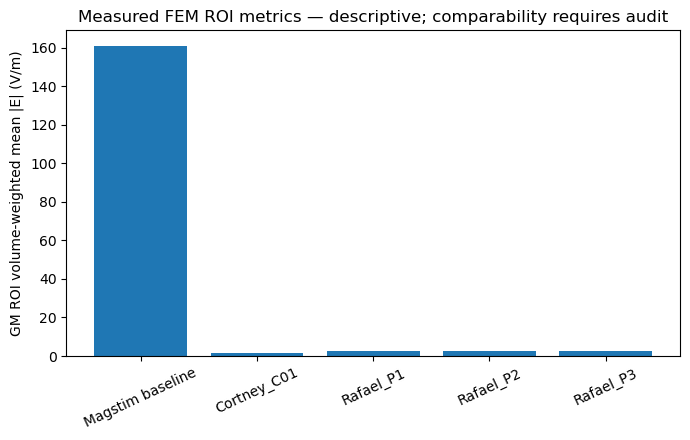

Controlled comparison withheld; resolve the audit issues before making performance claims.


In [8]:
reference = metrics.loc[metrics['case']==MAGSTIM_MSH.stem] if len(metrics) else pd.DataFrame()
reference_verified = all([bool(REFERENCE_COIL_FILE.strip()),bool(REFERENCE_COIL_SOURCE.strip()),
                          bool(REFERENCE_PLACEMENT.strip()),bool(REFERENCE_ORIENTATION.strip()),
                          REFERENCE_DIDT_A_PER_S is not None,REFERENCE_SCALP_OFFSET_MM is not None])
team_verified = bool(len(audit_df)) and bool((audit_df.status=='PASS').all())
can_claim_controlled = bool(len(reference)) and reference_verified and team_verified
print('Reference source/parameters verified:',reference_verified)
print('Team handoff passes all audits:',team_verified)
print('Controlled comparison authorized:',can_claim_controlled)
if len(metrics):
    fig,ax=plt.subplots(figsize=(max(7,len(metrics)*1.3),4.5))
    plot_labels = [next((label for label, p in CASE_MESHES.items() if p is not None and str(Path(p).resolve()).casefold() == str(Path(mesh_path).resolve()).casefold()), 'Magstim baseline' if str(Path(mesh_path).resolve()).casefold() == str(MAGSTIM_MSH.resolve()).casefold() else Path(mesh_path).parent.name) for mesh_path in metrics['mesh_path']]
    ax.bar(plot_labels,metrics['mean_E_V_per_m']);ax.set_ylabel('GM ROI volume-weighted mean |E| (V/m)')
    ax.set_title('Measured FEM ROI metrics — descriptive; comparability requires audit')
    ax.tick_params(axis='x',rotation=25);fig.tight_layout()
    fig.savefig(OUTPUT/'measured_roi_fields.png',dpi=180);plt.show()
if can_claim_controlled:
    base=float(reference.iloc[0]['mean_E_V_per_m'])
    comparison=team[['case','mean_E_V_per_m']].copy()
    comparison['ratio_to_reference']=pd.to_numeric(comparison['mean_E_V_per_m'])/base
    comparison['percent_difference']=100*(comparison['ratio_to_reference']-1)
    comparison.to_csv(OUTPUT/'controlled_comparison.csv',index=False)
    print(comparison.to_string(index=False))
else:
    print('Controlled comparison withheld; resolve the audit issues before making performance claims.')

## Cell 7 — Check the handoff numbers against their source meshes

**Goal:** detect transcription mistakes, stale CSV entries, or mismatched cases.

**Critical detail:** Cortney's and Rafael's mesh files may have the **same filename**, even though they live in different directories. Therefore, this cell matches the **full original path**, not the basename. Matching by filename alone can silently pair the wrong cases.

**Do:** run the next cell. **Expect:** four matches with approximately **0% disagreement** if the handoff CSV was just generated from these meshes. A discrepancy should trigger a path/ROI/data review, not an arbitrary adjustment.

**Important limitation:** because the CSV and metrics may be generated by the same extraction code, this is an **internal reproducibility / handoff-consistency check**, not an independent validation of the FEM physics.
**How to interpret the check:** all four rows should match when the handoff was generated from the same meshes. That verifies the case-to-path mapping and catches accidental mismatches; it is **not independent FEM solver validation** because the handoff and this check share the same extracted metrics. Keep the scientific provenance audit separate.


In [9]:
# Cell 7 — Cross-check the team handoff against extracted mesh metrics.
# This checks numerical consistency, NOT an independent rerun of the FEM solver.
# Important: different folders can contain meshes with identical filenames.
if 'mesh_path' not in metrics.columns:
    raise ValueError('Cell 4 must provide the full mesh_path for each metric.')

by_path = {
    str(Path(row['mesh_path']).resolve()).casefold(): float(row['mean_E_V_per_m'])
    for _, row in metrics.iterrows()
}
cross = []
for row in team.itertuples(index=False):
    case = getattr(row, 'case', '')
    original_path = str(getattr(row, 'mesh_file', ''))
    key = str(Path(original_path).resolve()).casefold()
    if key not in by_path:
        cross.append({'case':case,'mesh_file':original_path,'reported':np.nan,
                      'recomputed':np.nan,'absolute_percent_disagreement':np.nan,
                      'within_1_percent':False,'status':'UNMATCHED SOURCE PATH'})
        continue
    measured = by_path[key]
    reported = pd.to_numeric(getattr(row, 'mean_E_V_per_m', np.nan), errors='coerce')
    rel = (100 * abs(reported - measured) / abs(measured)
           if np.isfinite(reported) and measured != 0 else np.nan)
    cross.append({'case':case,'mesh_file':original_path,'reported':reported,
                  'recomputed':measured,'absolute_percent_disagreement':rel,
                  'within_1_percent':bool(rel <= 1) if np.isfinite(rel) else False,
                  'status':'MATCHED' if np.isfinite(rel) else 'REVIEW'})

cross_df = pd.DataFrame(cross,columns=['case','mesh_file','reported','recomputed',
    'absolute_percent_disagreement','within_1_percent','status'])
cross_df.to_csv(OUTPUT/'independent_recalculation_check.csv',index=False)
print(cross_df[['case','reported','recomputed','absolute_percent_disagreement',
                'within_1_percent','status']].to_string(index=False)
      if len(cross_df) else 'No team cases to cross-check.')


       case  reported  recomputed  absolute_percent_disagreement  within_1_percent  status
Cortney_C01  1.809869    1.809869                            0.0              True MATCHED
  Rafael_P1  2.612401    2.612401                            0.0              True MATCHED
  Rafael_P2  2.812810    2.812810                            0.0              True MATCHED
  Rafael_P3  2.673750    2.673750                            0.0              True MATCHED


### Cell 8 — Read Brandon's optimization results and provenance

**Goal:** understand what Brandon optimized, which FEM datasets supplied the candidate fields, and which constraints were used.

**Do:** run the next cell. It reads the existing candidate-comparison CSV and provenance JSON **without changing them**. Look for Rafael's P1/P2/P3 vector mesh paths, target coordinates, radius, reference $dI/dt$, baseline weights, optimized weights, and optimization status.

**Interpretation rule:** an optimized *weighted combination of field vectors* is not equivalent to adding field magnitudes. The physics uses $\mathbf E_{\mathrm{total}}=\sum_k a_k\mathbf E_k$, and only then $|\mathbf E_{\mathrm{total}}|$. Also, a single-coil candidate with a different excitation budget is not a budget-matched control.

**Your deliverable:** explain Brandon's data lineage in two or three sentences: Rafael FEM vectors → weighted field combination → target/surface/off-target metrics → constrained candidate comparison.

In [10]:
if BRANDON_CSV.is_file():
    brandon_table=pd.read_csv(BRANDON_CSV)
    print('Brandon comparison rows:',len(brandon_table))
    print(brandon_table.head(12).to_string(index=False))
else:
    brandon_table=pd.DataFrame()
    print('PENDING: Brandon comparison CSV not found:',BRANDON_CSV)
if BRANDON_PROVENANCE.is_file():
    brandon_provenance=json.loads(BRANDON_PROVENANCE.read_text(encoding='utf-8'))
    print('Brandon provenance:',json.dumps(brandon_provenance,indent=2,default=str)[:4000])
else:
    print('PENDING: Brandon provenance JSON not found:',BRANDON_PROVENANCE)


Brandon comparison rows: 5
   candidate  a1  a2           a3  sum_a   target  surface  offtarget
equal_budget 0.5 0.5 5.000000e-01    1.5 1.226624 0.342684   0.405420
   optimized 0.5 1.0 1.762833e-09    1.5 2.688320 0.350234   0.385367
     P1_only 1.0 0.0 0.000000e+00    1.0 2.612401 0.244808   0.292529
     P2_only 0.0 1.0 0.000000e+00    1.0 2.812810 0.249243   0.252627
     P3_only 0.0 0.0 1.000000e+00    1.0 2.673750 0.271150   0.301316
Brandon provenance: {
  "input_meshes": {
    "P1": "C:\\Users\\gothi\\OneDrive - Arizona State University\\ASU_School_Stuff\\EEE488_Capstone\\NFF5_PR2_C20_P1_E_v01.msh",
    "P2": "C:\\Users\\gothi\\OneDrive - Arizona State University\\ASU_School_Stuff\\EEE488_Capstone\\NFF5_PR2_C20_P2_E_v01.msh",
    "P3": "C:\\Users\\gothi\\OneDrive - Arizona State University\\ASU_School_Stuff\\EEE488_Capstone\\NFF5_PR2_C20_P3_E_v01.msh"
  },
  "target_mni_mm": [
    -38.0,
    44.0,
    26.0
  ],
  "target_subject_mm": [
    -33.71040725708008,
    70.74802398

## Cell 9 — Produce your scientific decision memo

**Goal:** turn technical checks into a report-ready conclusion a mentor can trust.

**Do:** run the next cell. It writes `validation_summary.md` with a decision of either **CONTROLLED COMPARISON READY** or **PROVISIONAL**. The decision is calculated from the audit, not your personal preference.

**In your own words, explain:** (1) which datasets were successfully read, (2) what numerical results reproduced, (3) which metadata remain unverified, and (4) what additional documentation is needed before performance claims. Keep ROI mean $|E|$ separate from focality, penetration depth, and clinical efficacy.
**Execution order matters:** run Cell 7 before Cell 9. Cell 7 creates `cross_df`, which the decision memo needs. Do not replace missing verification with a fabricated zero or mark any audit as PASS manually.


In [11]:
status='CONTROLLED COMPARISON READY' if can_claim_controlled else 'PROVISIONAL — EVIDENCE / INPUTS INCOMPLETE'
lines=[f'# NFF5 PR2 — Aaron validation summary',f'Generated UTC: {datetime.datetime.now(datetime.timezone.utc).isoformat()}',
       f'**Decision: {status}**','',f'- Subject: {HEAD_MODEL_ID}',f'- MNI ROI: {MNI_CENTER.tolist()}, radius {ROI_RADIUS_MM:g} mm',
       f'- SimNIBS: {SIMNIBS_VERSION}',f'- FEM meshes processed: {len(metrics)}; mesh errors: {len(errors)}',
       f'- Commercial coil provenance and settings verified: {reference_verified}',
       f'- Team handoff audit passed: {team_verified}',f'- Mesh/CSV numerical matches: {int(cross_df["within_1_percent"].sum())} of {len(team)} team cases (same extraction; not independent FEM validation)','',
       '## Interpretation guide',
       'State whether the reference is an authentic documented Magstim model or an approximate figure-eight surrogate.',
       'Describe what is matched (head, ROI, stimulation, placement, orientation) and what remains unmatched.',
       'Interpret ROI mean |E| separately from focality, field depth, and clinical outcome.',
       'Identify unresolved mismatches and request corrections before publication.',
       'A simulation agreement check does not independently validate the physical coil or clinical efficacy.']
(OUTPUT/'validation_summary.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')
print('\n'.join(lines));print('\nOutputs:',OUTPUT)

# NFF5 PR2 — Aaron validation summary
Generated UTC: 2026-10-31T16:41:18.495415+00:00
**Decision: PROVISIONAL — EVIDENCE / INPUTS INCOMPLETE**

- Subject: ernie
- MNI ROI: [-38.0, 44.0, 26.0], radius 10 mm
- SimNIBS: 4.6.0
- FEM meshes processed: 5; mesh errors: 0
- Commercial coil provenance and settings verified: True
- Team handoff audit passed: False
- Mesh/CSV numerical matches: 4 of 4 team cases (same extraction; not independent FEM validation)

## Interpretation guide
State whether the reference is an authentic documented Magstim model or an approximate figure-eight surrogate.
Describe what is matched (head, ROI, stimulation, placement, orientation) and what remains unmatched.
Interpret ROI mean |E| separately from focality, field depth, and clinical outcome.
Identify unresolved mismatches and request corrections before publication.
A simulation agreement check does not independently validate the physical coil or clinical efficacy.

Outputs: C:\Users\aaron\Desktop\EEE488\PR2\aar

## Aaron's PR2 acceptance checklist

Before handing your work to Victor, verify the following:

- [ ] Cell 1 points to **your actual files**; no data were copied or FEM simulations rerun.
- [ ] You can explain the difference between MNI and Ernie subject coordinates.
- [ ] You can explain in one sentence why our ROI is a 10 mm **radius** and why its GM volume is smaller than the full sphere.
- [ ] You know which source mesh produced each ROI value and where the SHA-256 inventory is saved.
- [ ] You can explain why a `REVIEW` flag does **not** mean a failed simulation.
- [ ] You can distinguish a descriptive chart from a controlled commercial benchmark.
- [ ] You have reviewed Brandon's comparison and its link to Rafael's vector FEM data.
- [ ] You have written a short plain-English decision summary identifying remaining evidence requests.

**Send Victor:** the notebook, `validation_summary.md`, the CSV audit/cross-check tables, and your brief interpretation. If the result remains PROVISIONAL, report it accurately.

## Bonus concept — why we cannot add three scalar magnitudes

When coil fields are combined, the **vectors** add:

$$\mathbf E_{\mathrm{total}}(\mathbf r)=\sum_{k=1}^{3}a_k\mathbf E_k(\mathbf r).$$

The magnitude of the sum is **not generally** the sum of magnitudes. Opposing vectors can cancel. This short code cell illustrates that point with two opposite vectors. You don't need to optimize anything here; the takeaway is why Brandon needed Rafael's **vector** fields rather than only the scalar `.msh` ROI means.

In [12]:
a=np.array([80.,0.,0.]); b=np.array([-80.,0.,0.])
print('Correct combined |E|:',np.linalg.norm(a+b),'V/m')
print('Incorrect sum of |E|:',np.linalg.norm(a)+np.linalg.norm(b),'V/m')
assert np.isclose(np.linalg.norm(a+b),0.)



Correct combined |E|: 0.0 V/m
Incorrect sum of |E|: 160.0 V/m


## Final readiness check — leave a traceable record

**Goal:** write a compact machine-readable status summary for the team. Run the final cell to create `master_readiness.json`. A `False` under provenance or controlled-comparison evidence is a request for documentation, not permission to change the underlying result.

**Finished:** save the notebook with **Ctrl+S**, then share your summary and questions with Victor. The next project step is documentation and interpretation, **not** another FEM run.

In [13]:
readiness={
 'subject_transform_available':subject_center is not None,
 'reference_mesh_present':MAGSTIM_MSH.is_file(),
 'real_mesh_metrics_extracted':len(metrics)>0,
 'reference_provenance_documented':reference_verified,
 'controlled_comparison_evidence_gate':can_claim_controlled,
 'mesh_csv_numerical_matches':int(cross_df['within_1_percent'].sum()),
 'mesh_csv_cases_checked':len(cross_df)
}
(OUTPUT/'master_readiness.json').write_text(json.dumps(readiness,indent=2),encoding='utf-8')
print(json.dumps(readiness,indent=2))


{
  "subject_transform_available": true,
  "reference_mesh_present": true,
  "real_mesh_metrics_extracted": true,
  "reference_provenance_documented": true,
  "controlled_comparison_evidence_gate": false,
  "mesh_csv_numerical_matches": 4,
  "mesh_csv_cases_checked": 4
}
